In [37]:
# Importing Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import joblib

In [38]:
# Loading the Dataset

df = pd.read_csv("Data.csv")
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [39]:
# Selecting Relevant Features

df = df[["price", "area", "bedrooms", "bathrooms", "stories", "mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "parking", "prefarea", "furnishingstatus"]]

In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [41]:
# Converting Categorical Values into Numerical Values
# Convert yes/no values into 1/0
# Convert furnishing status into numerical categories:
# unfurnished = 0, semi-furnished = 1, furnished = 2

df["mainroad"] = df["mainroad"].map({
    "yes": 1,
    "no": 0
})

df["guestroom"] = df["guestroom"].map({
    "yes": 1,
    "no": 0
})

df["basement"] = df["basement"].map({
    "yes": 1,
    "no": 0
})

df["hotwaterheating"] = df["hotwaterheating"].map({
    "yes": 1,
    "no": 0
})

df["airconditioning"] = df["airconditioning"].map({
    "yes": 1,
    "no": 0
})

df["prefarea"] = df["prefarea"].map({
    "yes": 1,
    "no": 0
})


df["furnishingstatus"] = df["furnishingstatus"].map({
    "unfurnished": 0,
    "semi-furnished": 1,
    "furnished": 2
})

In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    int64
 6   guestroom         545 non-null    int64
 7   basement          545 non-null    int64
 8   hotwaterheating   545 non-null    int64
 9   airconditioning   545 non-null    int64
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    int64
 12  furnishingstatus  545 non-null    int64
dtypes: int64(13)
memory usage: 55.5 KB


In [43]:
# Separating Features and Target

prediction = "price"
X = np.array(df.drop([prediction], axis=1))
Y = np.array(df[prediction])

In [44]:
# Checking the Shapes of X and Y

print(X.shape)
print(Y.shape)

(545, 12)
(545,)


In [45]:
# Splitting Data and Training the Linear Regression Model

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.1, random_state=18)
model = LinearRegression()
model.fit(x_train, y_train)
score = model.score(x_test, y_test)

In [46]:
print(score)

0.8028847368188405


In [47]:
# Generating Predictions

predictions = model.predict(x_test)

In [48]:
# Comparing Predicted and Actual Prices
for i in range(len(predictions)):
    print(f"Predictions: {predictions[i]}\t  VS\tReal: {y_test[i]}")

Predictions: 6448248.94338105	  VS	Real: 5460000
Predictions: 8062174.953898555	  VS	Real: 9681000
Predictions: 2692864.0855466155	  VS	Real: 4200000
Predictions: 5529467.765242215	  VS	Real: 4970000
Predictions: 3515651.089297822	  VS	Real: 3150000
Predictions: 2994858.6034155297	  VS	Real: 3850000
Predictions: 9575360.34625822	  VS	Real: 10150000
Predictions: 8079175.346484515	  VS	Real: 8540000
Predictions: 3886571.5889014457	  VS	Real: 3633000
Predictions: 7098588.288914103	  VS	Real: 8400000
Predictions: 7531301.26056814	  VS	Real: 9870000
Predictions: 4508312.637572971	  VS	Real: 3990000
Predictions: 4885681.224031306	  VS	Real: 5600000
Predictions: 3333500.3434836864	  VS	Real: 4305000
Predictions: 3793882.5969161	  VS	Real: 3150000
Predictions: 10461233.984020095	  VS	Real: 12250000
Predictions: 5255877.533228043	  VS	Real: 6650000
Predictions: 5767341.02245989	  VS	Real: 4200000
Predictions: 4517768.859325802	  VS	Real: 4007500
Predictions: 6468822.801552561	  VS	Real: 5600000

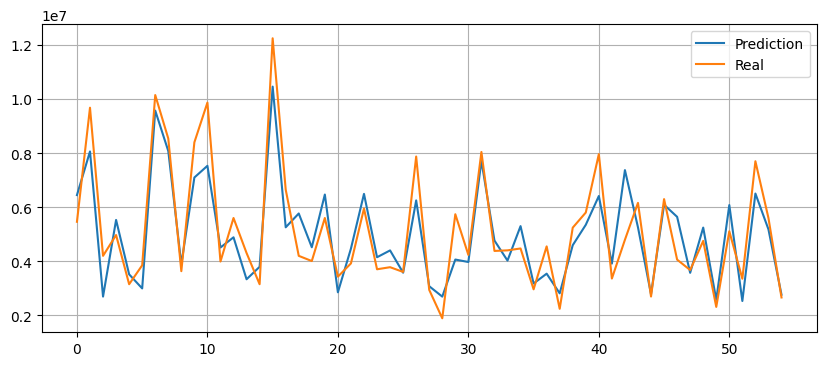

In [49]:
# Visualizing Predictions

plt.figure(figsize=(10, 4))
plt.plot(predictions, label="Prediction")
plt.plot(y_test, label="Real")
plt.legend()
plt.grid()
plt.show()

In [50]:
# Saving the Trained Model

model_name = "House-Prediction-model"
joblib.dump(model, model_name)

['House-Prediction-model']